# Matching Process Trees

### Build graph $G$ and find the connected components (process trees)
1. From the ```process_uber_summary``` table, build an ```igraph``` directed graph $G$ where each edge is of the form: ```parent PID --> child PID```
2. Get all (weak) connected components from $G$ -- those are the ```process trees``` (with one exception where a loop is present, which we drop), and save those in the **Trees** object
    * 99.98% of components are of size 2 (1,111,052  out of 1,111,278) ...
    * 210 process trees contain between 3 and 10k nodes
    * 15 have more then 10k nodes


In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
from collections import Counter
import igraph as ig
import gzip
import pickle
from functools import partial
from scipy.spatial import distance
import time

## our matching algorithm
import sys
import os
sys.path.insert(0,os.path.abspath('../Matching'))
import igraph_io as igio
import fast_match as fm  ## fast version
import needleman_wunsch_tree as nwt ## slower, more flexibility for scoring functions

## several utility functions
from acme_util import *


# Build process trees from the ```process_uber_summary``` table


In [3]:
process_summary = pd.read_parquet("Data/process_uber_summary.parquet", columns=['pid_hash', 'parent_pid_hash', 'process_name', 'user_name', 'red_team'] )
process_summary.head()


,pid_hash,parent_pid_hash,process_name,user_name,red_team
0,A86DB324303BBC24B4C279909AC5AD00,B066C89E8047845304C38E8BEE22AD90,powershell.exe,ACME\user10,1
1,C194ECED319F84EC8DAED02EE44FCE63,450735D5CC2CCEC4C8B12EC8818120E8,wmic.exe,None,0
2,FA50BB30E957D73120420F46B18AE167,450735D5CC2CCEC4C8B12EC8818120E8,wmic.exe,None,0
3,5803C60CEB8387DFA7ADA3E5E75E88FF,6FB634509A57999E72BCAFA74A8FFF29,wmic.exe,None,0
4,3BD26DAC90333D99453E9F506A514B1B,6FB634509A57999E72BCAFA74A8FFF29,wmic.exe,None,0


In [4]:
## we'll use those throughout
dct_username = dict(zip(process_summary.pid_hash,process_summary.user_name))
dct_label = dict(zip(process_summary.pid_hash,process_summary.red_team))
dct_processname = dict(zip(process_summary.pid_hash,process_summary.process_name))


In [5]:
%%time
Trees = extract_process_trees(process=process_summary, uid='pid_hash', parent_uid='parent_pid_hash',
                              min_tree_size=3, max_tree_size=100000, 
                              extra={'process_name':'process','user_name':'user','red_team':'redteam'})


CPU times: user 14.1 s, sys: 499 ms, total: 14.6 s
Wall time: 14.6 s


In [6]:
## for plotting - red_team nodes in red
Trees.graph.vs['label_color'] = 'black'
Trees.graph.vs['color'] = 'black'
for v in Trees.graph.vs:
    if dct_label.get(v['uid'],0)>0:
        v['label_color']='red'
        v['color']='red'

# EDA

In [7]:
len(Trees)

224

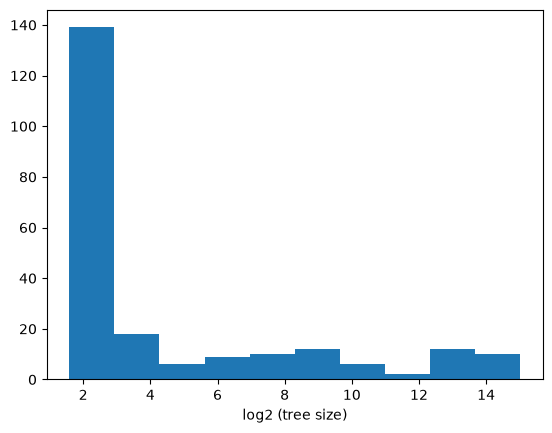

In [8]:
plt.hist([np.log2(x) for x in Trees.sizes()])
plt.xlabel('log2 (tree size)');


In [9]:
Trees.graph.vs[0]

igraph.Vertex(<igraph.Graph object at 0x7538f1579c50>, 0, {'uid': 'B066C89E8047845304C38E8BEE22AD90', 'tree': 0, 'tree_size': 23835, 'process': 'unknown', 'user': None, 'redteam': 1, 'label_color': 'red', 'color': 'red'})

### List all subtrees with known root process name


In [10]:
df_trees = pd.DataFrame()
for t in range(len(Trees)):
    _df = acme_list_process_subtrees(Trees.subgraph(t), dct_username, dct_label)
    _df.insert(loc=0, column='tree', value=t)
    df_trees = pd.concat([df_trees,_df])
df_trees


,tree,root,process,nodes,layers,leaves,bad3,bad9,bad25,redteam
0,0,2,ssm-agent-worker.exe,15904,3,15889,0,0,0,0
1,0,6,svchost.exe,769,3,761,0,0,0,0
2,0,39,ssm-document-worker.exe,4,2,3,0,0,0,0
3,0,52,svchost.exe,24,2,23,0,0,0,0
4,0,56,services.exe,22933,6,21039,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...
1,183,4,conhost.exe,4,4,1,0,0,0,0
0,186,0,conhost.exe,3,3,1,0,0,0,0
0,188,2,conhost.exe,3,3,1,0,0,0,0
0,206,1,conhost.exe,3,3,1,0,0,0,0


In [11]:
df_trees[ (df_trees.layers==5) & (df_trees.redteam>0) & (df_trees.nodes==10) ]

,tree,root,process,nodes,layers,leaves,bad3,bad9,bad25,redteam
192,2,12347,notepad++.exe,10,5,5,0,0,0,3
25,27,89,cmd.exe,10,5,6,0,0,0,6


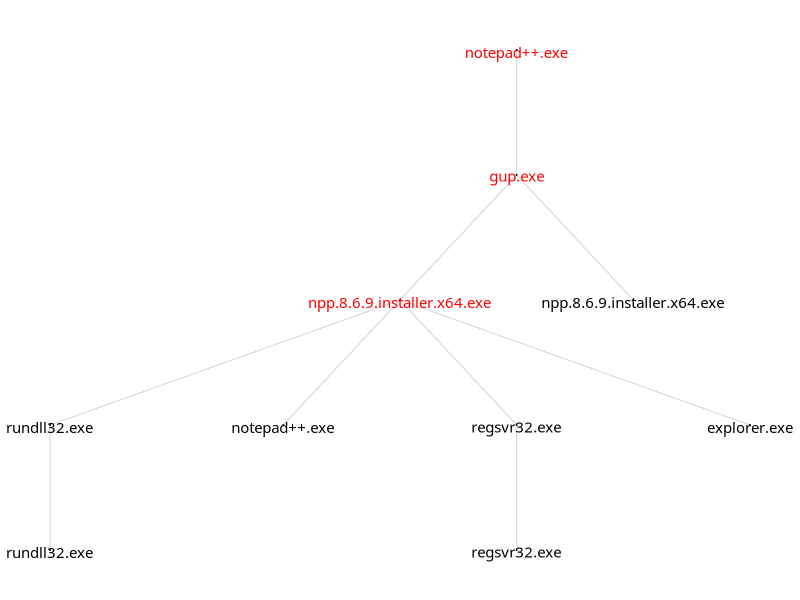

In [12]:
sg = acme_get_bfs_subtree(Trees, 2, 12347)
ig.plot(sg, target="_temp.png", bbox=(800,600), layout=sg.layout_reingold_tilford(), margin=50,
        vertex_size=1,
        vertex_label=sg.vs['process'],
        vertex_label_size=15,
        edge_color='lightgrey', edge_arrow_size=0)    
Image("_temp.png")


# Matching Experiment #1 -  top hits using various weight functions

* we select deep trees with up to 500 nodes (for display purpose)
* we compare "red trees" (with some redteam label) to "black trees"
* (optional) we report matches with at least one redteam label on the red tree matching path

We define different weight functions:

* default: exact match (between process names)
* redblack: exact match but only between redteam and non-readteam
* invfreq: exact match weighted by each process' inverse frequency (log scale)
* embed: exact match weighted by the process' distance in embedded space (built from numerical features)


In [13]:
## extract the subtrees
_df = df_trees[ (df_trees.layers>=7) & (df_trees.nodes<=500) ]
_trees = _df.tree.tolist()
_roots = _df.root.tolist()
TreeData_label = np.array(_df.redteam>0)
TreeData = []
for (t,r) in zip(_trees,_roots):
    sg = acme_get_bfs_subtree(Trees, t, r) 
    TreeData.append(igio.igraph_to_treedata(sg, phi_name='uid'))
Counter(TreeData_label)

Counter({np.False_: 144, np.True_: 32})

### (1a) default weight

This is the default with a binary score of 1 if the process names coincide, 0 otherwise.


In [14]:
## default weights
def _def(a, b, _process):
    return int(_process[a]==_process[b])
weight = partial(_def, _process=dct_processname)

best_pair = run_redblack_match(TreeData, TreeData_label, weight, dct_label, min_red_nodes=1)


Score: 8.0


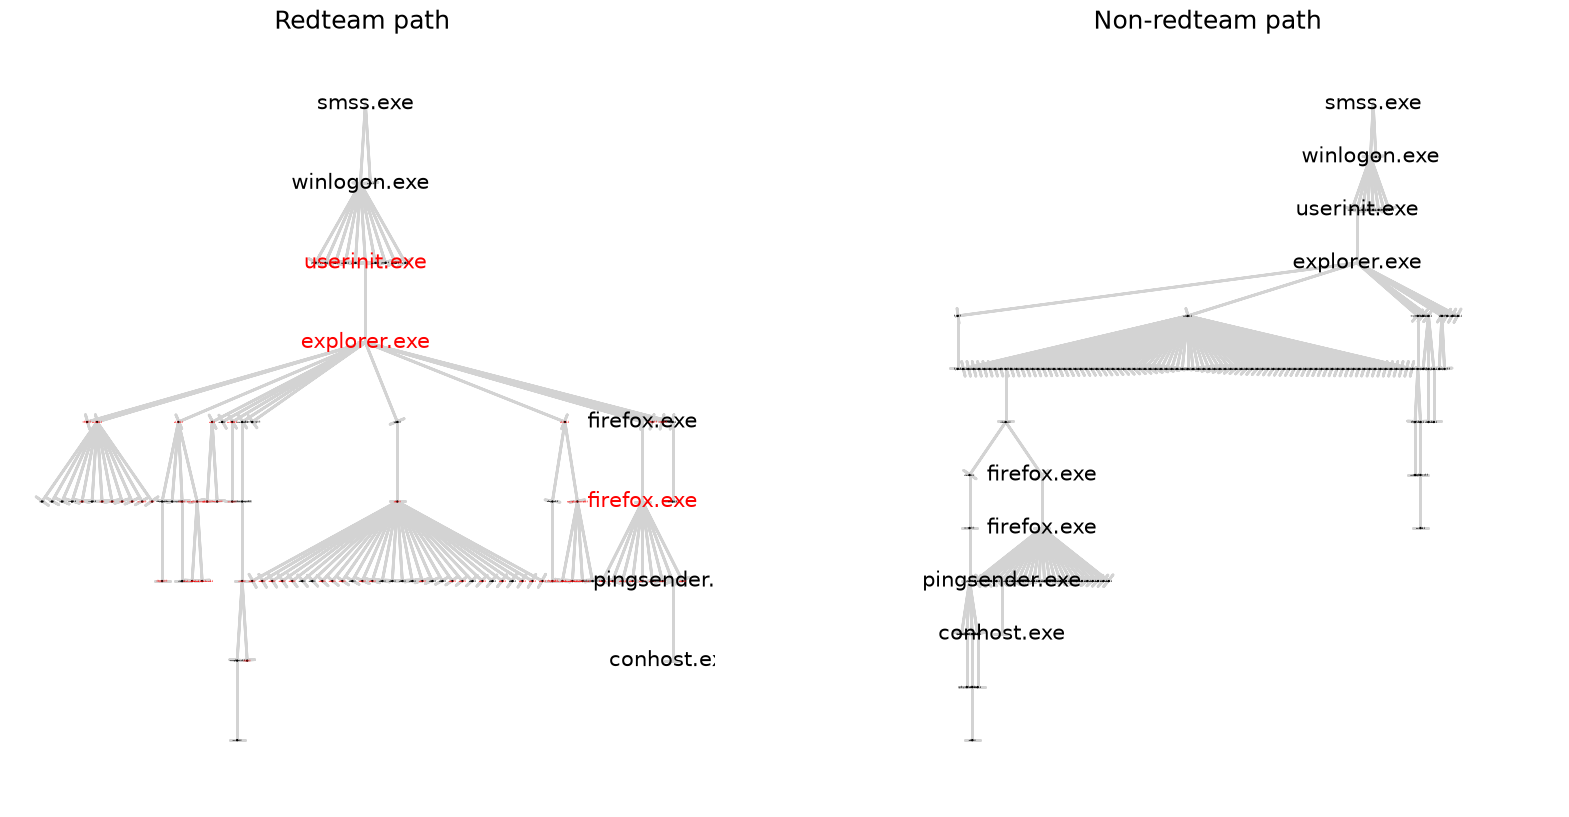

In [16]:
## plot best result
sg_red = acme_get_bfs_subtree(Trees, _trees[best_pair[0]], _roots[best_pair[0]]) 
sg_black = acme_get_bfs_subtree(Trees, _trees[best_pair[1]], _roots[best_pair[1]]) 
_sg_red = igio.igraph_to_treedata(sg_red, phi_name='uid')
_sg_black = igio.igraph_to_treedata(sg_black, phi_name='uid')
match = nwt.align_trees_algorithm1(_sg_red, _sg_black, w=weight)
plot_path((sg_red,sg_black), match.path_internal, margin=(0,.14))
print('Score:',match.score)

### (1b) redblack weight

A binary score of 1 if the process names coincide AND the labels (here, redteam) are different, 0 otherwise.


In [ ]:
## redblack
def _rb(a, b, _process, _label):
    return int(_process[a]==_process[b])*(_label[a]!=_label[b])
weight = partial(_rb, _process=dct_processname, _label=dct_label)

best_pair = run_redblack_match(TreeData, TreeData_label, weight, dct_label, min_red_nodes=1)


In [ ]:
## plot best result
sg_red = acme_get_bfs_subtree(Trees, _trees[best_pair[0]], _roots[best_pair[0]]) 
sg_black = acme_get_bfs_subtree(Trees, _trees[best_pair[1]], _roots[best_pair[1]]) 
_sg_red = igio.igraph_to_treedata(sg_red, phi_name='uid')
_sg_black = igio.igraph_to_treedata(sg_black, phi_name='uid')
match = nwt.align_trees_algorithm1(_sg_red, _sg_black, w=weight)
plot_path((sg_red,sg_black), match.path_internal, margin=(0,.14))
print('Score:',match.score)

### (1c) inverse fequency weight

A score in (0,1] inversely proportional (on log scale) to the process frequency if the process names coincide, 0 otherwise.


In [ ]:
## inverse frequency
proc_counts = Counter([dct_processname.get(v,'') for v in Trees.graph.vs['uid']])
dct_invfreq = {k: float(1/np.log2(v+1)) for k, v in proc_counts.items()} ## max score of 1 when v==1
def _if(a, b, _process, _freq):
    return int(_process[a]==_process[b])*(_freq[_process[a]])
weight = partial(_if, _process=dct_processname, _freq=dct_invfreq)

best_pair = run_redblack_match(TreeData, TreeData_label, weight, dct_label, min_red_nodes=1)


In [ ]:
## plot best result
sg_red = acme_get_bfs_subtree(Trees, _trees[best_pair[0]], _roots[best_pair[0]]) 
sg_black = acme_get_bfs_subtree(Trees, _trees[best_pair[1]], _roots[best_pair[1]]) 
_sg_red = igio.igraph_to_treedata(sg_red, phi_name='uid')
_sg_black = igio.igraph_to_treedata(sg_black, phi_name='uid')
match = nwt.align_trees_algorithm1(_sg_red, _sg_black, w=weight)
plot_path((sg_red,sg_black), match.path_internal, margin=(0,.14))
print('Score:',match.score)

In [ ]:
sum([x == 'vs_setup_bootstrapper.exe' for x in Trees.graph.vs['process']])


### (1d) embedded weight

A score in (0,1] inversely proportional to the PID's Manhattan distance in embedded space if the process names coincide, 0 otherwise.


In [ ]:
# embedded space
with gzip.open('Data/acme4_process_num_features_embedding_ecdf.pkl.gz', 'rb') as fp:
    embedding_ecdf = pickle.load(fp)
dim = len(next(iter(embedding_ecdf.values())))
def _es(a, b, _process, _emb):
    return int(_process[a]==_process[b])*(1-distance.cityblock(_emb[a],_emb[b])/dim)
    #return (1-distance.cityblock(_emb[a],_emb[b])/dim)
weight = partial(_es, _process=dct_processname, _emb=embedding_ecdf)

best_pair = run_redblack_match(TreeData, TreeData_label, weight, dct_label, min_red_nodes=1)


In [ ]:
## plot best result
sg_red = acme_get_bfs_subtree(Trees, _trees[best_pair[0]], _roots[best_pair[0]]) 
sg_black = acme_get_bfs_subtree(Trees, _trees[best_pair[1]], _roots[best_pair[1]]) 
_sg_red = igio.igraph_to_treedata(sg_red, phi_name='uid')
_sg_black = igio.igraph_to_treedata(sg_black, phi_name='uid')
match = nwt.align_trees_algorithm1(_sg_red, _sg_black, w=weight)
plot_path((sg_red,sg_black), match.path_internal, margin=(0,.14))
print('Score:',match.score)

In [ ]:
## PLOT in Embed space


In [ ]:
import umap
path = [x[0] for x in match.path_internal]
X = [embedding_ecdf[sg_red.vs[i]['uid']] for i in path]

path = [x[0] for x in match.path_internal]
X.extend([embedding_ecdf[sg_red.vs[i]['uid']] for i in path])

l = len(path)
c = np.repeat([0,1],l)

reducer = umap.UMAP(n_neighbors=3, metric='manhattan', min_dist=.25, spread=1.5)
embedding = reducer.fit_transform(np.array(X))

#plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(7,5))
ax.scatter(embedding[:, 0], embedding[:, 1], s=10, c=c, cmap='cool');
ax.set_title('ecdf embedding')
s = np.tile(np.arange(l),2)
for i in range(embedding.shape[0]):
    ax.annotate(s[i], (embedding[i, 0], embedding[i, 1]))

In [ ]:
angles = np.linspace(0, 2 * np.pi, 16, endpoint=False)
offx = 3*np.cos(angles)
offy = 3*np.sin(angles)

offx = 2*np.array([1,1,.5,.5,.5,0,0,1,-1,0,-.5,-.5,0,.25,-1,-.5])
offy = 3*np.array([1,1,1,1,1,1,1,1,-1,-1.5,-1,-1,-1,-1,-1,-1])


In [ ]:
path = [x[0] for x in match.path_internal]
l = len(path)
s = np.tile(np.arange(l),2)
cl = np.repeat(['red','blue'],l)
l = sg_red.vcount()
path.extend([x[1]+l for x in match.path_internal])


In [ ]:
X = [embedding_ecdf[x] for x in sg_red.vs['uid']]
X.extend([embedding_ecdf[x] for x in sg_black.vs['uid']])
c = np.concatenate( [np.repeat('red',sg_red.vcount()), np.repeat('blue',sg_black.vcount())] )
reducer = umap.UMAP(n_neighbors=7, metric='manhattan', min_dist=.25, spread=1.5, n_jobs=1, random_state=123)
embedding = reducer.fit_transform(np.array(X))

#plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(12,8))
ax.scatter(embedding[:, 0], embedding[:, 1], s=3, c=c );
ax.set_title('ecdf embedding')

for i in range(len(path)):
    ax.annotate(
        s[i],       # Le texte de l'annotation
        xy=(embedding[path[i], 0], embedding[path[i], 1]),          # Coordonnées (x, y) de la pointe de la flèche
        xytext=(embedding[path[i], 0] + offx[i], embedding[path[i], 1] + offy[i]), # Coordonnées (x, y) du texte (décalé pour laisser de la place)
        arrowprops=dict(
            facecolor=cl[i],          # Couleur de remplissage de la flèche
            arrowstyle="-|>",            # Style de la flèche (ex: "->", "-|>", "fancy")
            lw=1.0                      # Épaisseur de la ligne (line width)
        ),
        fontsize=12,
        color=cl[i],
        fontweight="bold"
    )

ax.margins(.1)

# Experiment #2 - timings

Using the default weights, we compare:
* the "slower" implementation as in experiment #1a
* a faster implementation (due to some pre-processing), and
* a beam search method


### (2a) speedup from experiment (1a)

- we run the matching algorithms 1000 times on the best scoring pair from experiment (1a)


In [50]:
## go back to experiment (1a) - what speedup can we get with the fast method?
_df = df_trees[ (df_trees.layers>=7) & (df_trees.nodes<=500) ]
_trees = _df.tree.tolist()
_roots = _df.root.tolist()
TreeData_label = np.array(_df.redteam>0)
TreeData = []
for (t,r) in zip(_trees,_roots):
    sg = acme_get_bfs_subtree(Trees, t, r) 
    TreeData.append(igio.igraph_to_treedata(sg, phi_name='uid'))
## default weights
def _def(a, b, _process):
    return int(_process[a]==_process[b])
weight = partial(_def, _process=dct_processname)
best_pair = run_redblack_match(TreeData, TreeData_label, weight, dct_label, min_red_nodes=1)
fast = fm.FastTreePathMatcher()
fast.fit_encoder(TreeData)
enc = [fast.encode_tree(t) for t in TreeData]

## slow
a = time.time()
for _ in range(1000):
    match = nwt.align_trees_algorithm1(TreeData[best_pair[0]], TreeData[best_pair[1]], w=weight)
slow_alg = time.time()-a

## fast
a = time.time()
for _ in range(1000):
    paths, score = fast.predict_encoded(enc[best_pair[0]], enc[best_pair[1]])
fast_alg = time.time()-a

print('time for 1000 runs, slow algorithm:',slow_alg,'fast algorithm:',fast_alg,'speedup:',slow_alg/fast_alg)


time for 1000 runs, slow algorithm: 18.334107160568237 fast algorithm: 0.06519508361816406 speedup: 281.2191678125274


### (2b) fast method - vary the minimum number of layers in the trees

By varying the minimum number of layers (from 3 to 7), we get different number of tree pairs (still comparing redteam and non-redteam).
We compute the running time of the matching algorithm as a function of the number of tree pairs we compare.


In [67]:
## extract the subtrees
BS = []

for nl in [3,4,5,6,7]:
    for nn in [500]:
        _df = df_trees[ (df_trees.layers>=nl) & (df_trees.nodes<=nn) ]
        _trees = _df.tree.tolist()
        _roots = _df.root.tolist()
        _leaves = _df.leaves.tolist()
        TreeData_label = np.array(_df.redteam>0)
        num_tree_pairs = ( sum(TreeData_label==False) * sum(TreeData_label) )
        
        ## faster implementation
        a = time.time()
        TreeData = []
        for (t,r) in zip(_trees,_roots):
            sg = acme_get_bfs_subtree(Trees, t, r) 
            TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))
        fast_preproc = time.time()-a
        
        def run_redblack_match_fast(TreeData, _label):
            fast = fm.FastTreePathMatcher()
            fast.fit_encoder(TreeData)
            enc = [fast.encode_tree(t) for t in TreeData]
            best_score = 0
            num_leaves_pairs = 0
            for red in np.where(_label==True)[0]:
                for black in np.where(_label==False)[0]:
                    paths, score = fast.predict_encoded(enc[red], enc[black])
                    num_leaves_pairs += (_leaves[red]*_leaves[black])
                    if score > best_score:
                        best_score = score
            return best_score, num_leaves_pairs
        
        a = time.time()
        best_score, num_leaves_pairs = run_redblack_match_fast(TreeData, TreeData_label)
        fast_alg = time.time()-a
        BS.append([num_tree_pairs, num_leaves_pairs, fast_preproc, fast_alg, best_score])
        print(nl, nn, num_tree_pairs, num_leaves_pairs, fast_preproc, fast_alg, best_score)


3 500 671242 330432065 88.4251618385315 12.022748947143555 9.0
4 500 100434 212316454 46.41998553276062 2.721644878387451 9.0
5 500 27755 147293118 28.96818733215332 1.2161922454833984 9.0
6 500 10485 104426223 19.73915982246399 0.7064661979675293 9.0
7 500 4608 65269422 13.189679145812988 0.41373157501220703 9.0


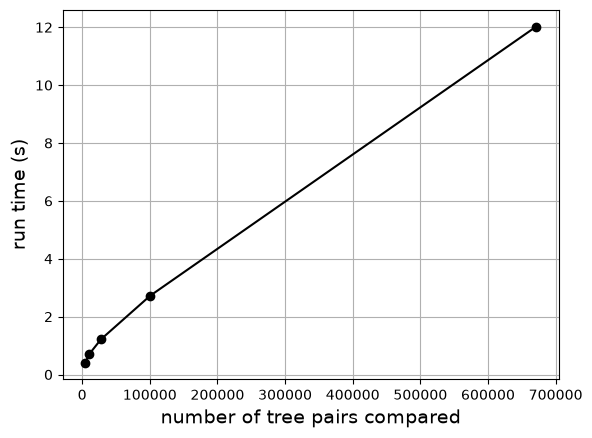

In [68]:
_BS = pd.DataFrame(BS, columns=['pairs','leaves','preproc','time','best'])

plt.plot(_BS.pairs, _BS.time, 'o-', color='black')
plt.grid()
plt.xlabel('number of tree pairs compared', fontsize=14)
plt.ylabel('run time (s)', fontsize=14)
plt.show()


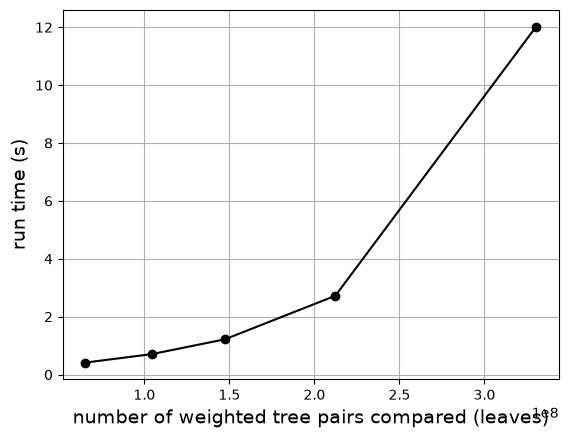

In [70]:
plt.plot(_BS.leaves, _BS.time, 'o-', color='black')
plt.grid()
plt.xlabel('number of weighted tree pairs compared (leaves)', fontsize=14)
plt.ylabel('run time (s)', fontsize=14)
plt.show()


### fast method - vary the number of trees

By varying the tree sizes, we get different number of tree pairs (still comparing redteam and non-redteam), but we also get trees with large number of paths.
We compute the running time of the matching algorithm as a function of the number of weighted tree pairs we compare, where each tree weight is its number of leaves.


In [74]:
## extract the subtrees
BS = []

for nl in [7]:
    for nn in [100,500,1000,2500,5000, 10000]:
        _df = df_trees[ (df_trees.layers>=nl) & (df_trees.nodes<=nn) ]
        _trees = _df.tree.tolist()
        _roots = _df.root.tolist()
        _leaves = _df.leaves.tolist()
        TreeData_label = np.array(_df.redteam>0)
        num_tree_pairs = ( sum(TreeData_label==False) * sum(TreeData_label) )
        
        ## faster implementation
        a = time.time()
        TreeData = []
        for (t,r) in zip(_trees,_roots):
            sg = acme_get_bfs_subtree(Trees, t, r) 
            TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))
        fast_preproc = time.time()-a
        
        def run_redblack_match_fast(TreeData, _label):
            fast = fm.FastTreePathMatcher()
            fast.fit_encoder(TreeData)
            enc = [fast.encode_tree(t) for t in TreeData]
            best_score = 0
            num_leaves_pairs = 0
            for red in np.where(_label==True)[0]:
                for black in np.where(_label==False)[0]:
                    paths, score = fast.predict_encoded(enc[red], enc[black])
                    num_leaves_pairs += (_leaves[red]*_leaves[black])
                    if score > best_score:
                        best_score = score
            return best_score, num_leaves_pairs
        
        a = time.time()
        best_score, num_leaves_pairs = run_redblack_match_fast(TreeData, TreeData_label)
        fast_alg = time.time()-a
        BS.append([num_tree_pairs, num_leaves_pairs, fast_preproc, fast_alg, best_score])
        print(nl, nn, num_tree_pairs, num_leaves_pairs, fast_preproc, fast_alg, best_score)


7 100 480 300736 3.6385133266448975 0.015770435333251953 6.0
7 500 4608 65269422 13.200220584869385 0.41358304023742676 9.0
7 1000 7238 266953316 33.58696985244751 1.5367257595062256 12.0
7 2500 8580 749315920 65.6535587310791 3.513767957687378 13.0
7 5000 8745 844612314 65.96440315246582 3.855437755584717 13.0
7 10000 9222 2736928467 124.02904152870178 11.426462650299072 13.0


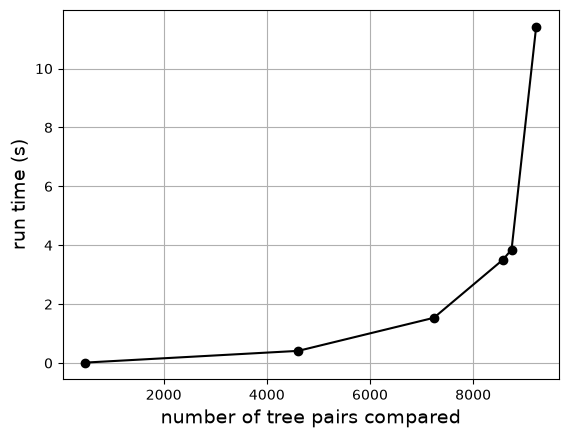

In [75]:
_BS = pd.DataFrame(BS, columns=['pairs','leaves','preproc','time','best'])

plt.plot(_BS.pairs, _BS.time, 'o-', color='black')
plt.grid()
plt.xlabel('number of tree pairs compared', fontsize=14)
plt.ylabel('run time (s)', fontsize=14)
plt.show()


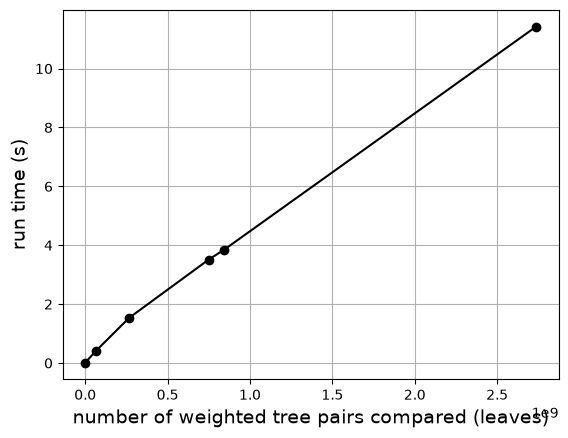

In [76]:
plt.plot(_BS.leaves, _BS.time, 'o-', color='black')
plt.grid()
plt.xlabel('number of weighted tree pairs compared (leaves)', fontsize=14)
plt.ylabel('run time (s)', fontsize=14)
plt.show()


### TODO

- beam search method - compare results with the above default

# Experiment #3 - classification of root processes

- we first use a random set of trees as templates
- we then use batches and try to use template trees that are ``different'' from the ones already chosen
- we use the fast implementation with default weights


In [201]:
import random
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay #, precision_score, recall_score,  roc_curve, auc


In [160]:
n_class = 6
_df = df_trees[(df_trees.nodes<=5000) & (df_trees.layers>=3)]
common_proc = [x[0] for x in Counter(_df.process).most_common(n_class)]
_df = _df[_df.process.isin(common_proc)]
_df = _df.reset_index()


In [208]:
%%time
Graphs = []
TreeData = []
T = list(_df.tree)
R = list(_df.root)
P = np.array(_df.process)
for i in range(len(T)):
    sg = acme_get_bfs_subtree(Trees, T[i], R[i])
    Graphs.append(sg)
    TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))

CPU times: user 1min 18s, sys: 58 ms, total: 1min 18s
Wall time: 1min 18s


In [221]:
## encode all trees
fast = fm.FastTreePathMatcher()
fast.fit_encoder(TreeData)
enc = [fast.encode_tree(t) for t in TreeData]


In [ ]:
def generate_bool_vector(n_true, n_false):
  vector = [True] * n_true + [False] * n_false
  random.shuffle(vector)
  return np.array(vector)
label_map = {v:k for k,v in enumerate(common_proc)}


In [278]:
## parameters
L = []

for n_templates in [25,50,75,100]:
    for min_occ in [0,1,2,3]:
        print(n_templates, min_occ)
        for rep in range(30):
            ## pick templates
            mo = -1
            while mo < min_occ: ## force at least this number for each class
                is_template = generate_bool_vector(n_templates, _df.shape[0]-n_templates)
                _c = Counter(P[is_template] )
                ctr = {k: _c[k] for k in common_proc}
                mo = min(ctr.values())
            ## score each pair "template-nontemplate'
            templates = np.where(is_template==True)[0].tolist()
            others = np.where(is_template==False)[0].tolist()
            Score = np.zeros(shape=(len(templates), len(others)))
            
            for i in range(len(templates)):
                for j in range(len(others)):
                    paths, score = fast.predict_encoded(enc[templates[i]], enc[others[j]])
                    Score[i,j] = score
            ## train RF
            X = Score.T.tolist()
            y = [P[i] for i in others]
            X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=123)
            rf = RandomForestClassifier(n_jobs=16, random_state=123)
            rf.fit(X_train, y_train);
            ## apply to test set
            y_pred = rf.predict(X_test)
            L.append([n_templates, min_occ, sum(y_pred != y_test)])


25 0
25 1
25 2
25 3
50 0
50 1
50 2
50 3
75 0
75 1
75 2
75 3
100 0
100 1
100 2
100 3


### (3a) random set of templates

In [285]:
_results = pd.DataFrame(L, columns=['templates','min','errors'])
_results[_results['min']==0].groupby(by='templates').mean('errors')


,min,errors
templates,,
25,0.0,10.133333
50,0.0,7.966667
75,0.0,6.033333
100,0.0,4.866667


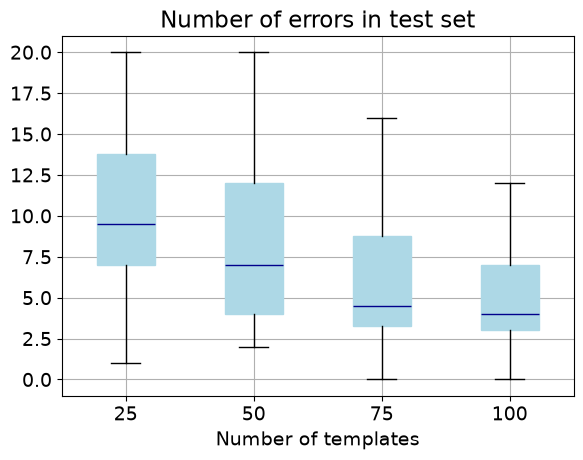

In [286]:
props = dict(boxes="lightblue", whiskers="black", medians="DarkBlue", caps="black")
_results[_results['min']==0].boxplot(column='errors', by='templates', showfliers=False, color=props, patch_artist=True)
plt.suptitle('')
plt.title('Number of errors in test set')
plt.xlabel('Number of templates');


### (3b) chosen set of templates

In [287]:
_results = pd.DataFrame(L, columns=['templates','min','errors'])
_results[_results['templates']==25].groupby(by='min').mean('errors')


,templates,errors
min,,
0,25.0,10.133333
1,25.0,8.633333
2,25.0,7.266667
3,25.0,5.566667


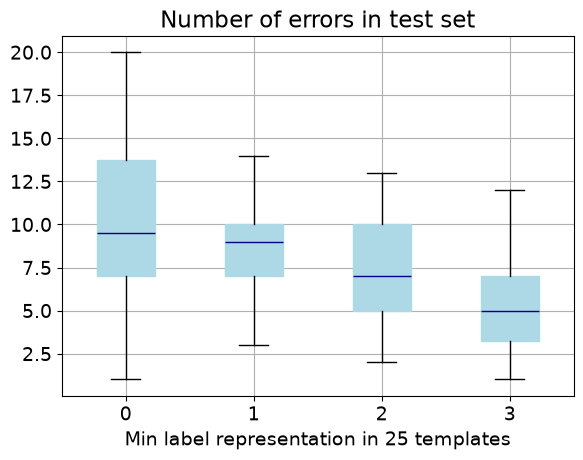

In [288]:
props = dict(boxes="lightblue", whiskers="black", medians="DarkBlue", caps="black")
_results[_results['templates']==25].boxplot(column='errors', by='min', showfliers=False, color=props, patch_artist=True)
plt.suptitle('')
plt.title('Number of errors in test set')
plt.xlabel('Min label representation in 25 templates');


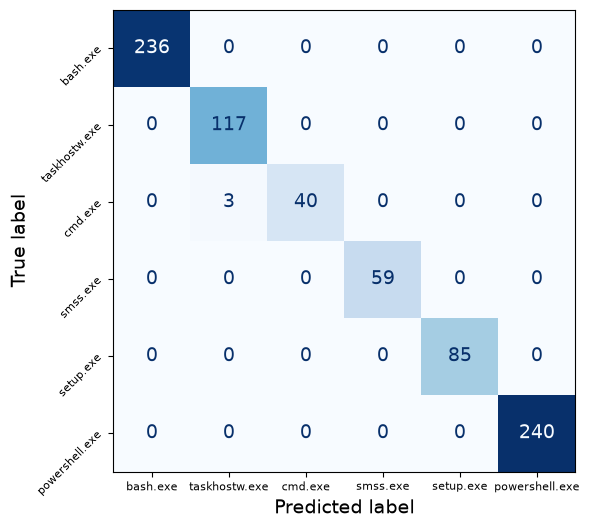

In [289]:
## example 
cm = confusion_matrix(y_test,y_pred)
fig,ax = plt.subplots(figsize=(9,6))
plt.rcParams.update({'font.size': 14}) # Change to your desired size
disp = ConfusionMatrixDisplay(confusion_matrix=cm, 
                              display_labels=list(label_map.keys())
                             )
disp.plot(colorbar=False, cmap='Blues', ax=ax)
plt.xticks(fontsize=8)
plt.yticks(rotation=45, fontsize=8)
plt.show()


# Experiment #4 - Filepaths
